In [42]:
"""
experiments/diff_fidelity_random.py
"""
import sys
sys.path.append("../")

from __future__ import annotations
import math
from dataclasses import dataclass
from typing import Iterable, Tuple, List, Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import qiskit

from qiskit import QuantumCircuit
from qiskit.circuit.random import random_clifford_circuit
from pipeline.config import PipelineConfig
from pipeline import run_full_scan, run_specific_scan
from simulator.config_presets import StandardSimulator

In [47]:
Perm = List[Tuple[int, int]]

def generate_compact_perm(q: int) -> Perm:
    """
    Compact = fill patches by pairs in order:
      [(0,0), (0,1), (1,0), (1,1), (2,0), (2,1), ...]
    Requires q to be even (each patch holds 2 logicals).
    """
    v = q
    if q % 2 != 0:
      v = q + 1
    return [(i // 2, i % 2) for i in range(v)]

def generate_sparse_perm(q: int) -> Perm:
    """
    Sparse = each qubit gets its own patch in index 0:
      [(0,0), (1,0), (2,0), ..., (q-1,0)]
    """
    return [(i, 0) for i in range(q)]

def perm_to_tuple(perm_like) -> Tuple[Tuple[int, int], ...]:
    """Normalize to tuple-of-tuples of ints for reliable equality/Dict keys."""
    return tuple((int(a), int(b)) for a, b in list(perm_like))


In [51]:
@dataclass
class CircuitDiffs:
    best_minus_avg: float
    best_minus_compact: Optional[float]
    best_minus_sparse: Optional[float]

def ensure_rows_for_perms(
    tcirc: QuantumCircuit,
    config: PipelineConfig,
    df: pd.DataFrame,
    perm_col: str,
    target_perms: List[Perm],
) -> pd.DataFrame:
    """
    If specific permutations are missing from df, run a small specific scan to add them.
    Return a new dataframe that contains (at least) those permutations.
    """
    have = set(df[perm_col].apply(perm_to_tuple))
    need = None # [p for p in target_perms if perm_to_tuple(p) not in have]

    print(have)
    print(need)

    if need:
        # Run a quick specific scan just for the missing ones
        spec_record = run_specific_scan(program_circuit=tcirc, permutations=need, config=config)
        add_df = spec_record.dataframe
        # Concatenate & drop duplicates on permutation
        df = pd.concat([df, add_df], ignore_index=True)
        perm_norm_col = "_perm_norm_added"
        df[perm_norm_col] = df[perm_col].apply(perm_to_tuple)
        df = df.drop_duplicates(subset=[perm_norm_col]).drop(columns=[perm_norm_col])

    return df

def diffs_for_single_circuit(
    q: int,
    depth: int,
    target_basis: Iterable[str],
    config: PipelineConfig,
    seed: Optional[int] = None,
) -> CircuitDiffs:
    # 1) Random circuit, measure, transpile
    program_circuit: QuantumCircuit = random_clifford_circuit(q, depth, seed=seed)
    program_circuit.measure_all()

    tcirc = qiskit.transpile(
        program_circuit,
        basis_gates=list(target_basis),
        optimization_level=0,
    )

    # 2) Full scan
    record = run_full_scan(tcirc, config)
    df = record.dataframe.df.copy()

    metric_col = "logical_total_variation_distance"
    perm_col = "perm_key"

    # Normalize permutation column for reliable matching
    df["_perm_norm"] = df[perm_col].apply(perm_to_tuple)

    # 3) Ensure compact & sparse rows exist (add via specific scan if missing)
    compact_perm = generate_compact_perm(q)
    sparse_perm = generate_sparse_perm(q)
    df = ensure_rows_for_perms(tcirc, config, df, perm_col, [compact_perm, sparse_perm])

    # Recompute normalized column if we concatenated above
    if "_perm_norm" not in df.columns:
        df["_perm_norm"] = df[perm_col].apply(perm_to_tuple)

    # 4) Compute metrics
    best = df[metric_col].max()
    avg = df[metric_col].mean()

    # Find compact/sparse rows (may be absent in pathological cases)
    compact_key = perm_to_tuple(compact_perm)
    sparse_key = perm_to_tuple(sparse_perm)

    compact_rows = df.loc[df["_perm_norm"] == compact_key, metric_col]
    sparse_rows  = df.loc[df["_perm_norm"] == sparse_key, metric_col]

    compact_val = float(compact_rows.iloc[0]) if len(compact_rows) else np.nan
    sparse_val  = float(sparse_rows.iloc[0]) if len(sparse_rows) else np.nan

    def pct_diff(best, ref):
        return 100 * (best - ref) / ref if ref != 0 else np.nan

    return CircuitDiffs(
        best_minus_avg = pct_diff(best, avg),
        best_minus_compact = None if math.isnan(compact_val) else pct_diff(best, compact_val),
        best_minus_sparse  = None if math.isnan(sparse_val)  else pct_diff(best, sparse_val),
    )

def run_avg_perm_diffs(
    m: int,
    q: int,
    depth: int,
    target_basis: Iterable[str],
    config: PipelineConfig,
    seed0: Optional[int] = None,
):
    diffs: List[CircuitDiffs] = []
    for i in range(m):
        seed = None if seed0 is None else (seed0 + i)
        diffs.append(diffs_for_single_circuit(q, depth, target_basis, config, seed=seed))

    # Aggregate (ignore Nones)
    bma = np.array([d.best_minus_avg for d in diffs], dtype=float)

    bmc = np.array(
        [np.nan if d.best_minus_compact is None else d.best_minus_compact for d in diffs],
        dtype=float,
    )
    bms = np.array(
        [np.nan if d.best_minus_sparse is None else d.best_minus_sparse for d in diffs],
        dtype=float,
    )

    avg_best_minus_avg     = float(np.nanmean(bma))
    avg_best_minus_compact = float(np.nanmean(bmc))
    avg_best_minus_sparse  = float(np.nanmean(bms))

    # Bar chart
    labels = [
        "Best − Average",
        "Best − Compact",
        "Best − Sparse",
    ]
    values = [
        avg_best_minus_avg,
        avg_best_minus_compact,
        avg_best_minus_sparse,
    ]

    plt.figure(figsize=(6, 4))
    plt.bar(labels, values)
    plt.title(f"Average differences over {m} random circuits (q={q}, depth={depth})")
    plt.ylabel(pick_metric_ylabel())
    plt.tight_layout()
    plt.show()

    # Also return the raw numbers if you want to log them
    return {
        "avg_best_minus_average": avg_best_minus_avg,
        "avg_best_minus_compact": avg_best_minus_compact,
        "avg_best_minus_sparse":  avg_best_minus_sparse,
    }

def pick_metric_ylabel() -> str:
    # Cosmetic label for the y-axis (matches first available metric name)
    # You can hardcode if you prefer.
    return "Performance difference (same units as chosen metric)"

In [52]:
# Experiment params
m = 2            # number of random circuits to average over
q = 4             # number of logical qubits in program circuit
depth = 3        # depth for random_clifford_circuit
target_basis = ['x', 'z', 'h', 'rz', 'cx', 'cz', 'measure']

# Simulator / pipeline config
config = PipelineConfig(
    sim_config=StandardSimulator(repetitions=25_000),
    verbose=False,
    fault_tolerant=False,
)

results = run_avg_perm_diffs(
    m=m,
    q=q,
    depth=depth,
    target_basis=target_basis,
    config=config,
    seed0=7,   # optional reproducibility
)
print(results)

[permutations] Found 75 unique assignments (done)                              


Simulating circuits:   5%|▌         | 4/75 [00:10<03:01,  2.55s/ sim]


KeyboardInterrupt: 

[permutations] Found 19 unique assignments (done)                              


Simulating circuits: 100%|██████████| 19/19 [02:00<00:00,  6.32s/ sim]

{((0, 0), (0, 1), (1, 0)), ((0, 0), (0, 1), (1, 1)), ((0, 0), (1, 0), (2, 1)), ((1, 1), (0, 0), (2, 1)), ((2, 1), (0, 0), (1, 0)), ((0, 1), (1, 0), (0, 0)), ((1, 0), (0, 0), (0, 1)), ((1, 0), (0, 1), (0, 0)), ((0, 0), (2, 1), (1, 0)), ((0, 0), (1, 0), (0, 1)), ((0, 0), (1, 1), (2, 1)), ((0, 1), (1, 1), (0, 0)), ((1, 1), (0, 0), (0, 1)), ((1, 1), (0, 1), (0, 0)), ((0, 1), (0, 0), (1, 0)), ((0, 0), (1, 0), (2, 0)), ((0, 1), (0, 0), (1, 1)), ((0, 0), (1, 1), (0, 1)), ((1, 1), (2, 1), (0, 0))}
None



/var/folders/wg/x2lp9rgn2nnd1qlsjh51lwqr0000gn/T/ipykernel_19919/477319025.py:121: RuntimeWarning: Mean of empty slice
  avg_best_minus_compact = float(np.nanmean(bmc))


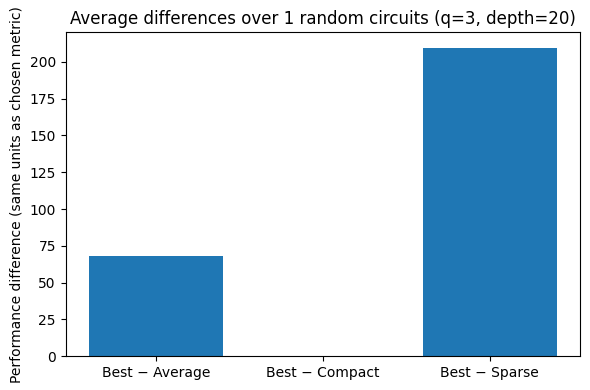

{'avg_best_minus_average': 67.93477477158787, 'avg_best_minus_compact': nan, 'avg_best_minus_sparse': 209.51462752588708}


In [56]:
from experiments.shared.example_circuits import n_ghz_state

# Experiment params
m = 1             # number of random circuits to average over
q = 3             # number of logical qubits in program circuit
depth = 20        # depth for random_clifford_circuit
target_basis = ['x', 'z', 'h', 'rz', 'cx', 'cz', 'measure']

# Simulator / pipeline config
config = PipelineConfig(
    sim_config=StandardSimulator(repetitions=25_000),
    verbose=False,
    fault_tolerant=False,
)

results = run_avg_perm_diffs(
    m=m,
    q=q,
    depth=depth,
    target_basis=target_basis,
    config=config,
    seed0=10,   # optional reproducibility
)
print(results)